#Import libraries



In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,f1_score
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import ConfusionMatrixDisplay

#Load data

In [3]:
file_id = '1WaMMcWZQbYIQXBVOwJZ0tSjDgw5PsXyR'
url = f'https://drive.google.com/uc?id={file_id}'


df = pd.read_csv(url)
rows ,columns =df.shape

print(f'Data Frame Rows ={rows}')
print(f'Data Frame Columns ={columns}')

Data Frame Rows =7043
Data Frame Columns =21


# Task 1 — Data Preparation

In this part, we explore the dataset, understand its structure, inspect the target variable, and check for missing values, duplicates, and unusual values.

Data Notes


1.   No missing Values ,No Duplicate Rows


1.   `TotalCharges` had blank strings → converted to numeric (few NaNs)



1.   Data Frame Rows =7043 , Data Frame Columns =21
2.   `customerID` is only an ID → drop before modelling









In [4]:
print('Frist 10 Rows')
df.head()

Frist 10 Rows


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print(f'Data Frame Rows ={rows}')
print(f'Data Frame Columns ={columns}')

Data Frame Rows =7043
Data Frame Columns =21


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [8]:
df['TotalCharges'].value_counts()

,count
TotalCharges,
,11
20.2,11
19.75,9
20.05,8
19.9,8
...,...
130.15,1
3211.9,1
7843.55,1


In [9]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

print(df['TotalCharges'].dtype)

float64


In [10]:
print('Missing Value')
df.isnull().mean().sort_values(ascending=False)*100

Missing Value


,0
TotalCharges,0.156183
gender,0.000000
SeniorCitizen,0.000000
Partner,0.000000
customerID,0.000000
Dependents,0.000000
tenure,0.000000
MultipleLines,0.000000
PhoneService,0.000000
OnlineSecurity,0.000000


In [11]:
print(f'Duplictae rows={df.duplicated().sum()}')


Duplictae rows=0


In [12]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


In [14]:
df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


In [15]:
categorical_cols=df.select_dtypes(include='object').columns.tolist()
print(categorical_cols)


['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [16]:
numerical_cols =df.select_dtypes(include='number').columns.tolist()
print(numerical_cols)

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [17]:
for col in categorical_cols:

    print(f"\n{col}:")
    print("Number of unique values:", df[col].nunique())
    print(df[col].value_counts(dropna=False))
    print('-------------------------------------------------------')


customerID:
Number of unique values: 7043
customerID
3186-AJIEK    1
7590-VHVEG    1
5575-GNVDE    1
4501-VCPFK    1
6075-SLNIL    1
             ..
1452-KIOVK    1
6713-OKOMC    1
7892-POOKP    1
6388-TABGU    1
9763-GRSKD    1
Name: count, Length: 7043, dtype: int64
-------------------------------------------------------

gender:
Number of unique values: 2
gender
Male      3555
Female    3488
Name: count, dtype: int64
-------------------------------------------------------

Partner:
Number of unique values: 2
Partner
No     3641
Yes    3402
Name: count, dtype: int64
-------------------------------------------------------

Dependents:
Number of unique values: 2
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
-------------------------------------------------------

PhoneService:
Number of unique values: 2
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
-------------------------------------------------------

MultipleLines:
Number of unique values: 3
Multipl

In [18]:
for col in numerical_cols:

    print(f"\n{col}:")
    print("Number of unique values:", df[col].nunique())
    print(df[col].value_counts(dropna=False))
    print('-------------------------------------------------------')


SeniorCitizen:
Number of unique values: 2
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
-------------------------------------------------------

tenure:
Number of unique values: 73
tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64
-------------------------------------------------------

MonthlyCharges:
Number of unique values: 1585
MonthlyCharges
20.05     61
19.85     45
19.95     44
19.90     44
20.00     43
          ..
42.40      1
97.90      1
116.40     1
31.65      1
39.05      1
Name: count, Length: 1585, dtype: int64
-------------------------------------------------------

TotalCharges:
Number of unique values: 6530
TotalCharges
NaN        11
20.20      11
19.75       9
20.05       8
19.90       8
           ..
130.15      1
3211.90     1
7843.55     1
2196.30     1
197.40      1
Name: count, Length: 6531, dtype: int64
----------------------------------------

No Need Data Cleaning as No missing values , Dublicted

# Task 2 — Data Cleaning
Drop `customerID`, encode target.  
Missing `TotalCharges` will be filled by median

In [19]:
median_TotalCharges=df['TotalCharges'].median()
df['TotalCharges'].fillna(median_TotalCharges ,inplace=True)

/tmp/ipykernel_3425/3153195483.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(median_TotalCharges ,inplace=True)


In [20]:
df.isnull().sum().sort_values(ascending=False)

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [21]:
df.drop_duplicates(inplace=True)

In [22]:
print(f'Duplictae rows={df.duplicated().sum()}')


Duplictae rows=0


In [23]:
df.drop('customerID', axis=1, inplace=True)

In [24]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Task 3: Feature Engineering


In [25]:
df['Churn'] = df['Churn'].map({
    'Yes': 1,
    'No': 0
})

In [26]:
df['Churn']

,Churn
0,0
1,0
2,1
3,0
4,1
...,...
7038,0
7039,0
7040,0
7041,1


# Task 4 — Data Visualization

Visualization helps us understand the numerical features, their distributions, relationships with the target variable, correlations, and possible outliers.



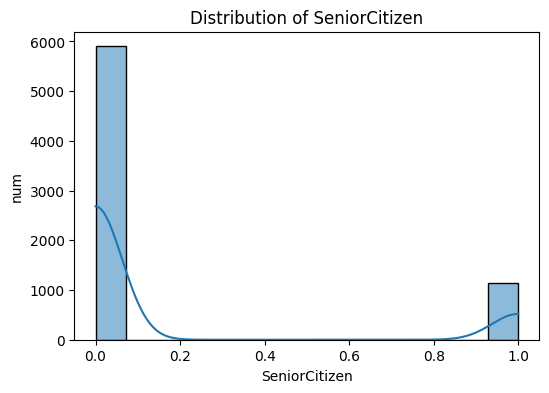

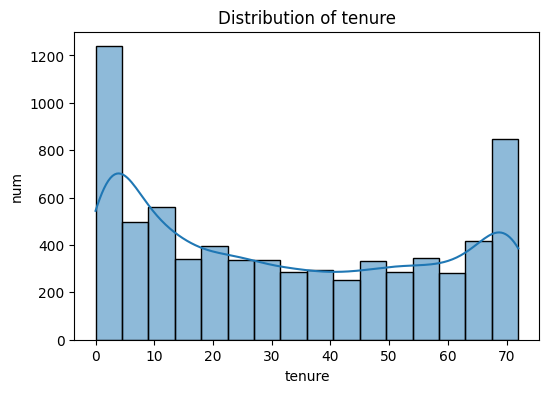

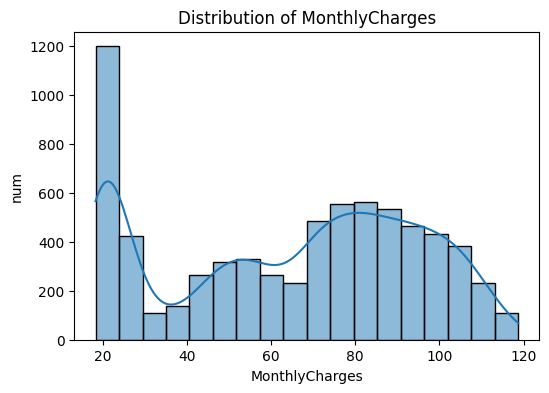

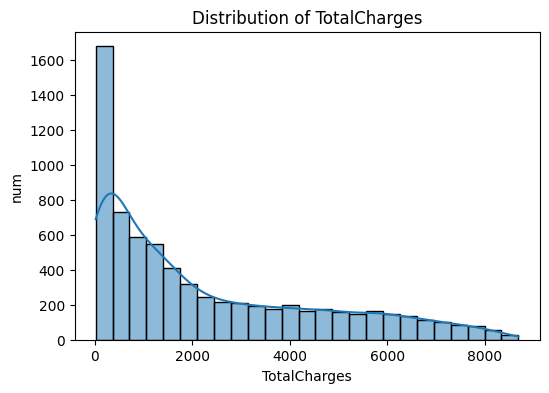

In [28]:
for col in numerical_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("num")
    plt.show()

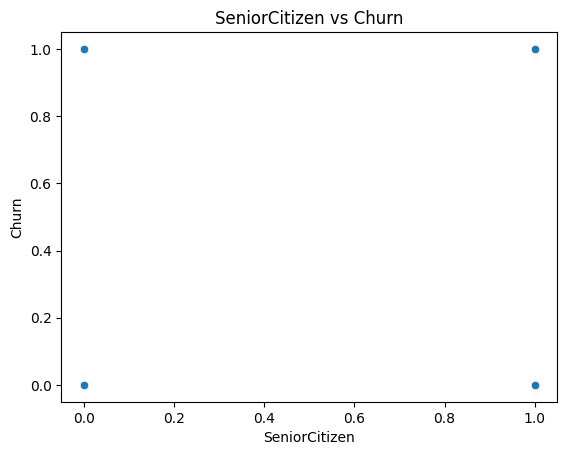

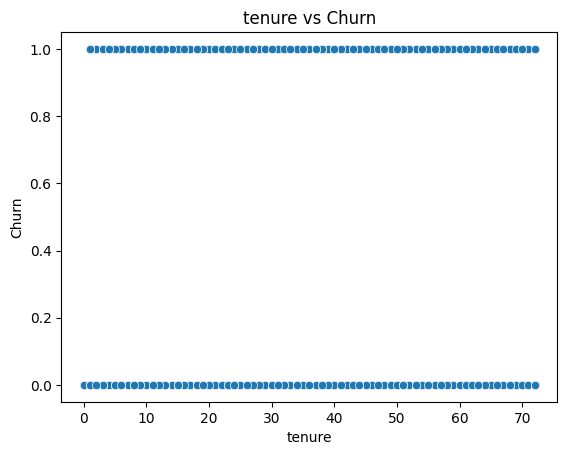

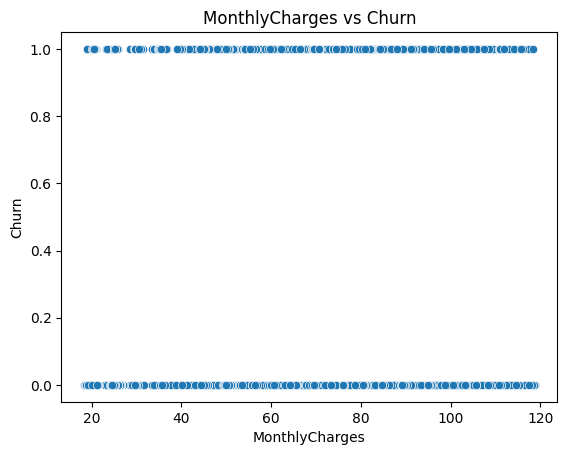

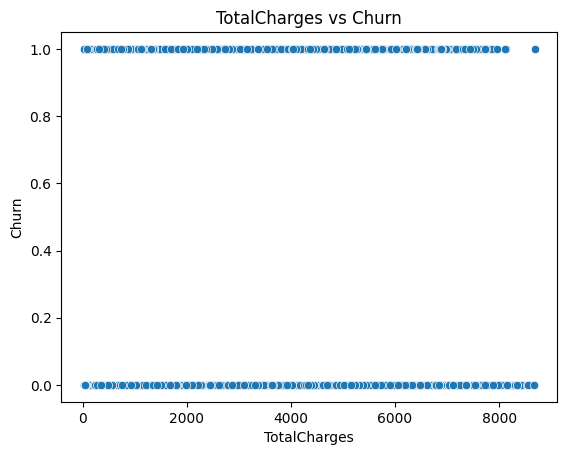

In [29]:
for col in numerical_cols:
    sns.scatterplot(x=df[col], y=df["Churn"])
    plt.xlabel(col)
    plt.ylabel("Churn")
    plt.title(f"{col} vs Churn")
    plt.show()

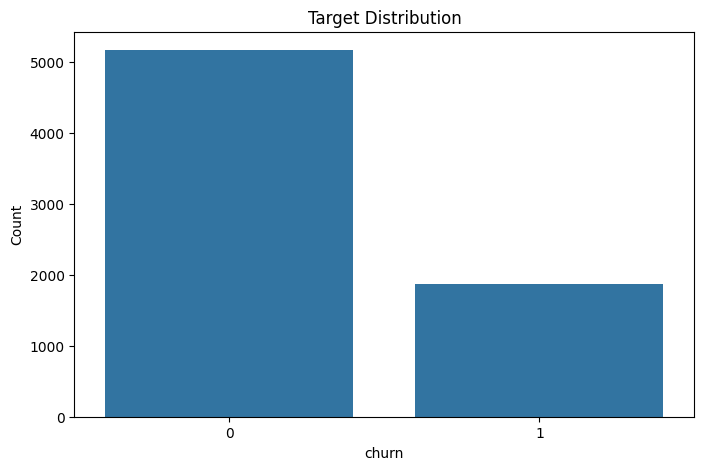

In [30]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=df['Churn'])

plt.title('Target Distribution')
plt.xlabel('churn')
plt.ylabel('Count')

plt.show()

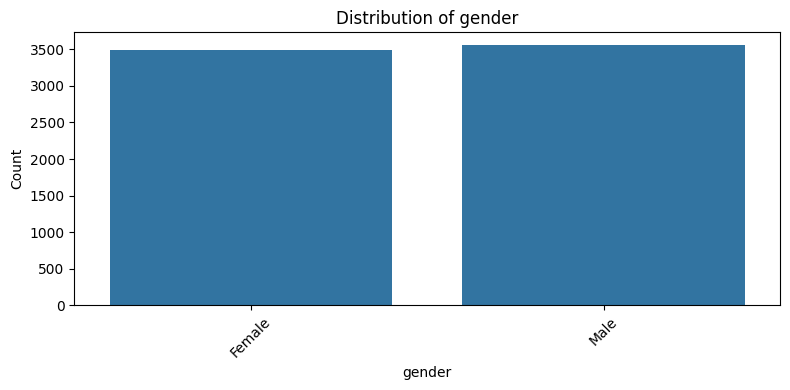

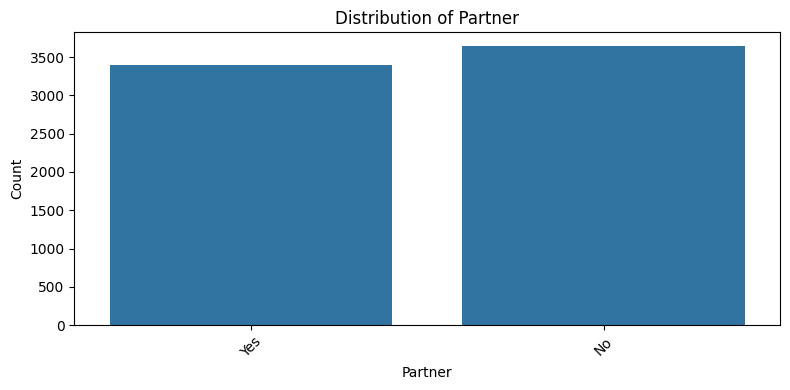

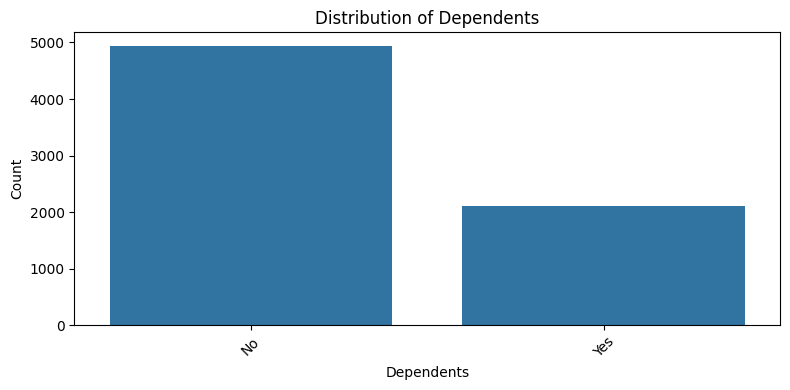

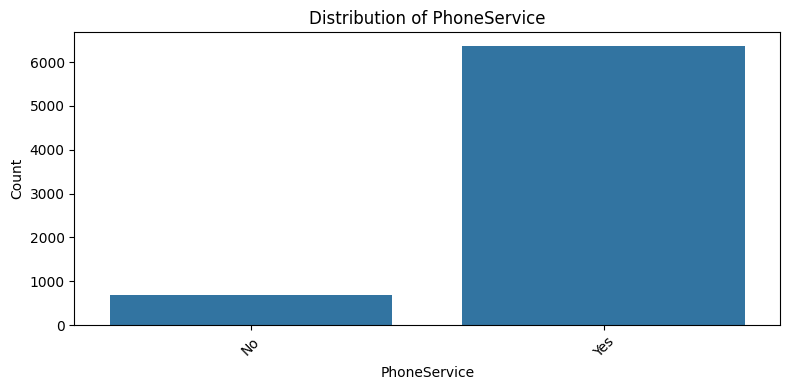

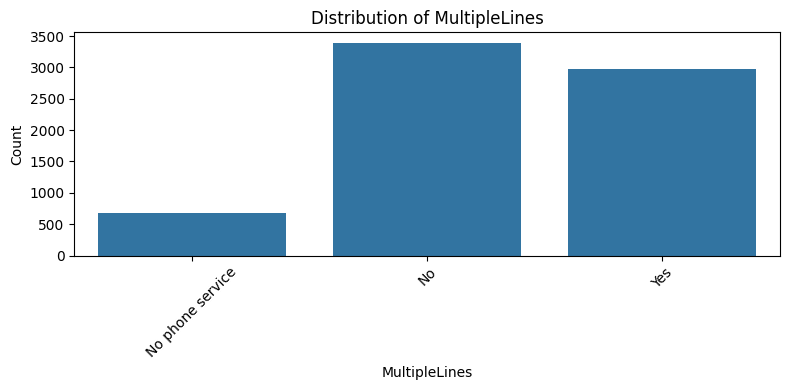

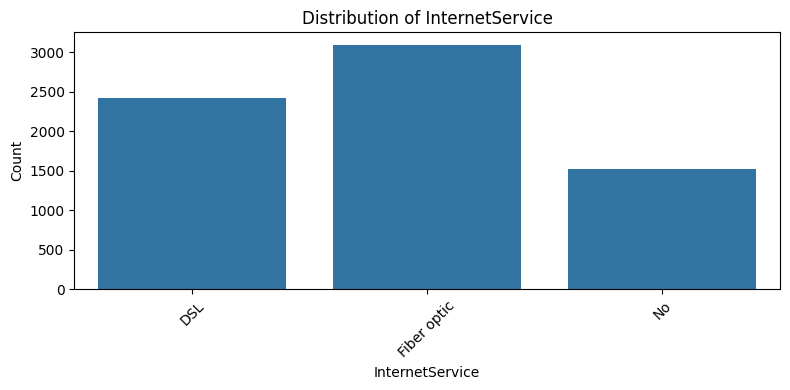

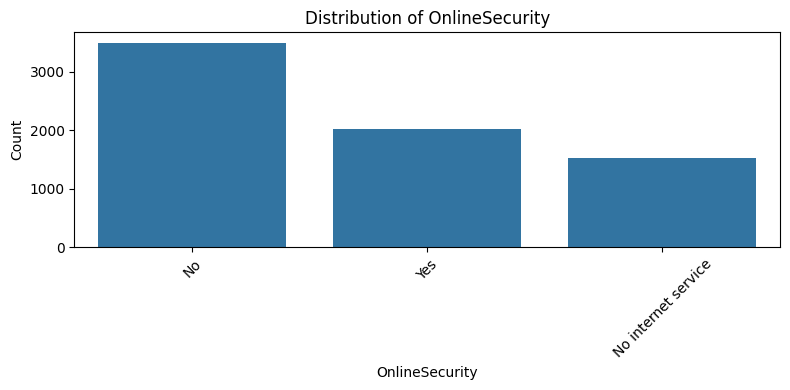

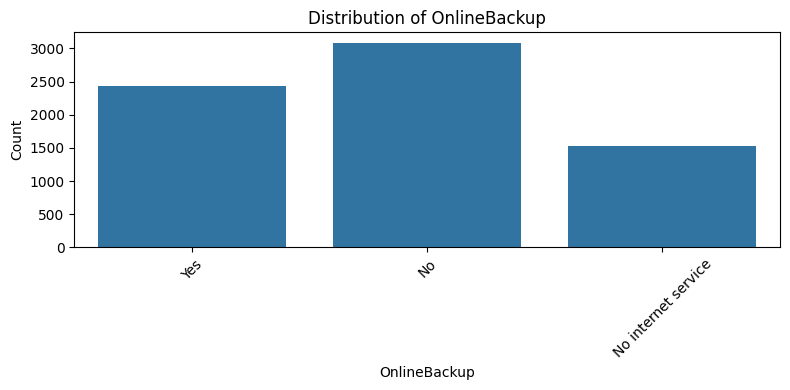

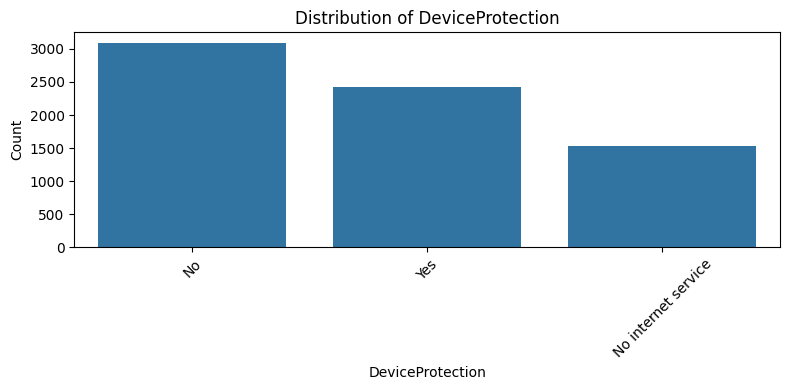

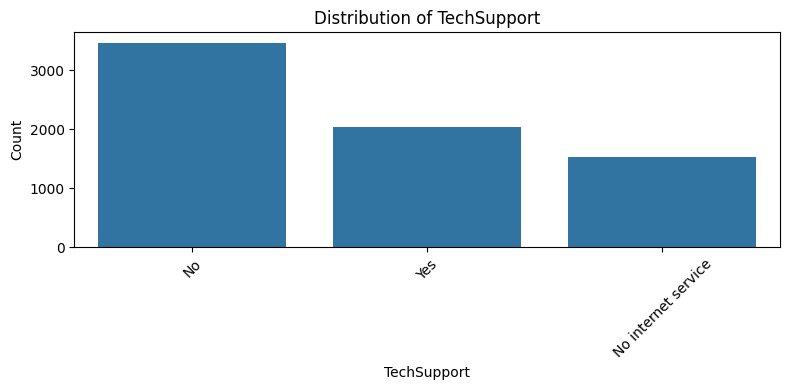

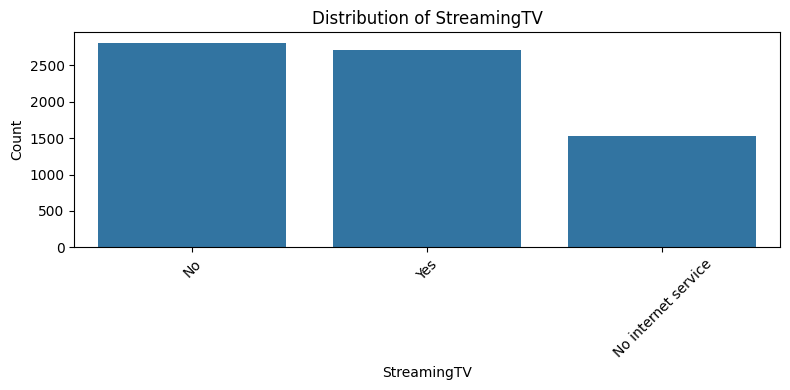

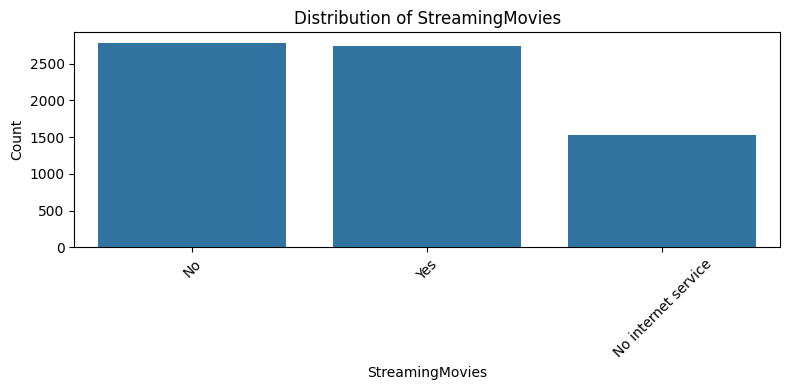

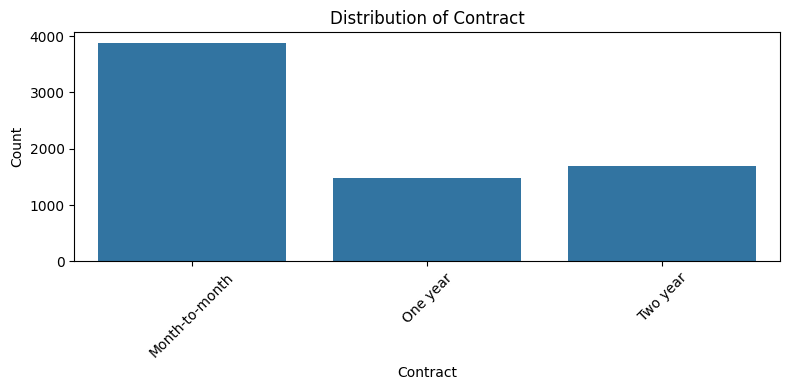

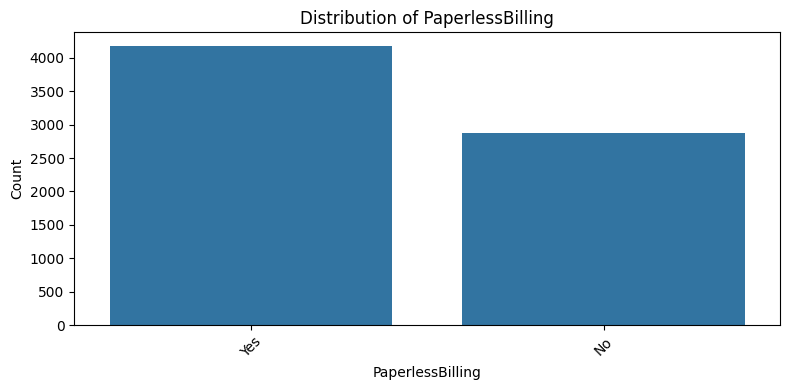

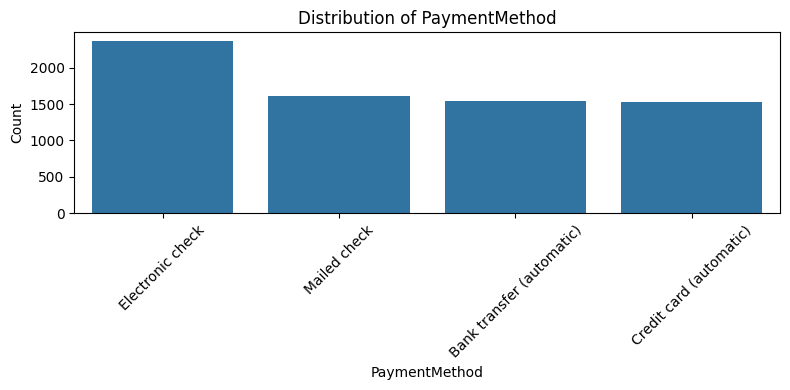

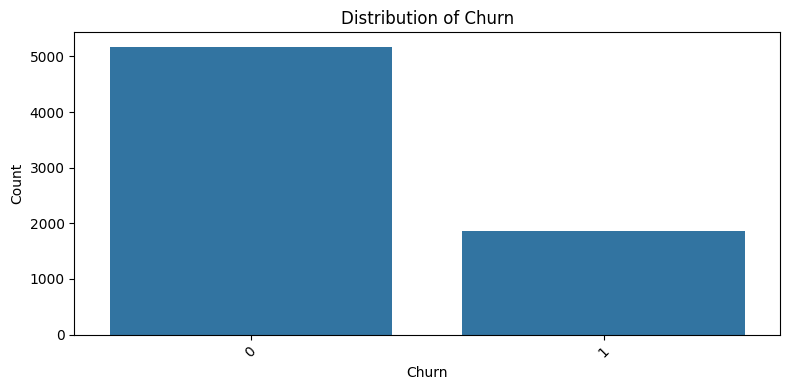

In [31]:
existing_categorical_cols = [col for col in categorical_cols if col in df.columns]

for col in existing_categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

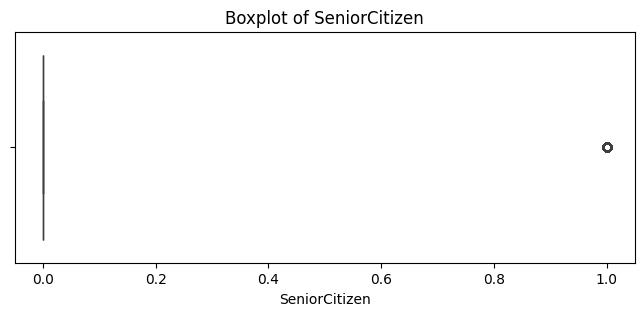

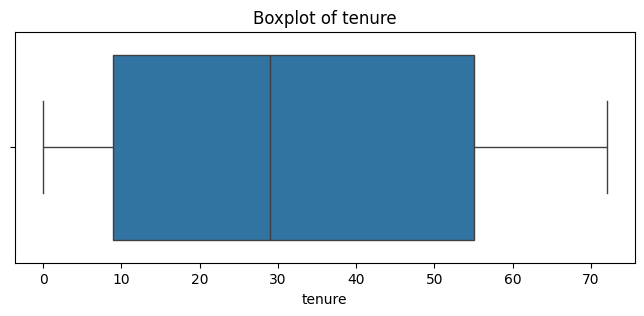

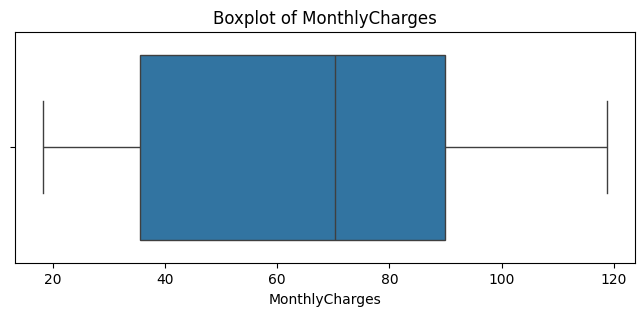

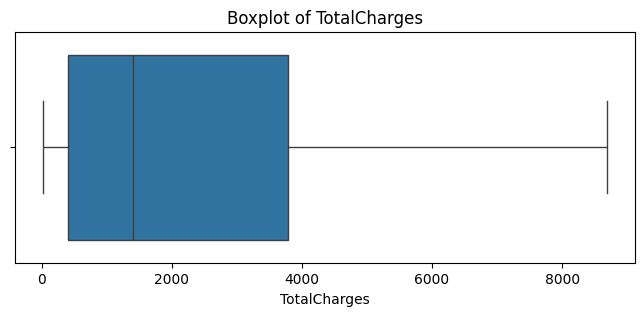

In [32]:
for col in numerical_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

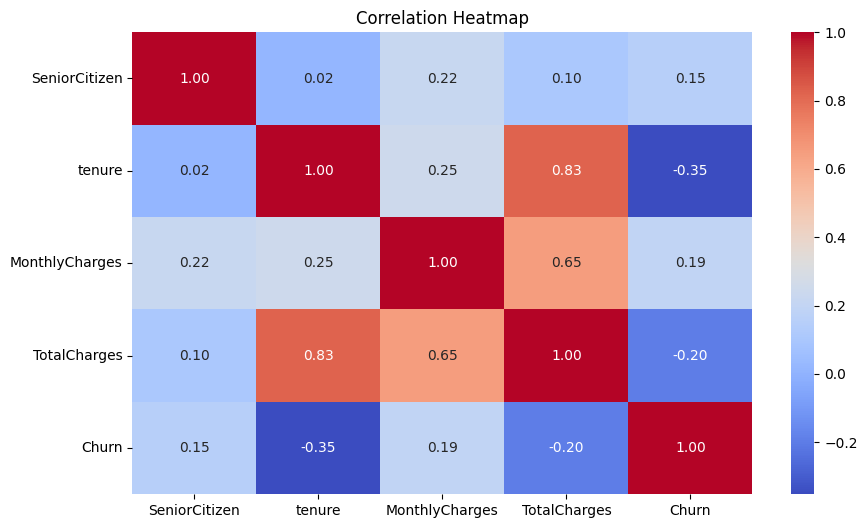

In [33]:
plt.figure(figsize=(10, 6))

corr = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

# Task 5 — Train/Test Split

We split the dataset into:

- **80% training data**
- **20% testing data**

In [34]:
from sklearn.model_selection import train_test_split

x=df.drop(columns=['Churn'])
y=df['Churn']

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.20,random_state=42 ,stratify=y)

print("X_train:", x_train.shape)
print("X_test :", x_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (5634, 19)
X_test : (1409, 19)
y_train: (5634,)
y_test : (1409,)


In [35]:
numerical_features = x_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = x_train.select_dtypes(include=['object']).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)


Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


# Task 6 — Feature Scaling and Encoding

In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


numerical_transformer=Pipeline(
    steps=[
        ('scaler',StandardScaler())
    ]
)

categorical_transformer=Pipeline(
    steps=[
        ('encoder',OneHotEncoder(handle_unknown='ignore'))
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# Task 7 — Training models

1. Logistic Regression Model
2. K-Nearest Neighbors (KNN) Model
3. Multiple Classification Models Comparison
Logistic Regression
Decision Tree
Random Forest
AdaBoost
KNN
4. Model Evaluation
Accuracy
Precision
Recall
F1-Score
Classification Report
Training vs. Testing Performance




In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression())
    ]
)


lr_model.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('model', LogisticRegression())])

In [40]:
y_predict_test = lr_model.predict(x_test)
y_predict_train = lr_model.predict(x_train)

In [42]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,classification_report
print(classification_report(y_test, y_predict_test))
print('----------------------------------------------------------')
print(classification_report(y_train, y_predict_train))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

----------------------------------------------------------
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      4139
           1       0.66      0.55      0.60      1495

    accuracy                           0.81      5634
   macro avg       0.75      0.72      0.74      5634
weighted avg       0.80      0.81      0.80      5634



In [43]:
from sklearn.neighbors import KNeighborsClassifier
#Create The LR Model
Knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier())
    ]
)
Knn_model.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('model', KNeighborsClassifier())])

In [44]:
y_predict_test = Knn_model.predict(x_test)
y_predict_train = Knn_model.predict(x_train)

In [45]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,classification_report
print(classification_report(y_test, y_predict_test))
print('----------------------------------------------------------')
print(classification_report(y_train, y_predict_train))

              precision    recall  f1-score   support

           0       0.84      0.83      0.84      1035
           1       0.55      0.57      0.56       374

    accuracy                           0.76      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.77      0.76      0.77      1409

----------------------------------------------------------
              precision    recall  f1-score   support

           0       0.88      0.90      0.89      4139
           1       0.71      0.66      0.68      1495

    accuracy                           0.84      5634
   macro avg       0.79      0.78      0.79      5634
weighted avg       0.83      0.84      0.84      5634



In [46]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import precision_score, recall_score, accuracy_score

models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'KNN': KNeighborsClassifier()

}

test_results = []
train_results = []

for name, model in models.items():
    print(name)

    model_pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('model', model)
        ]
    )

    model_pipeline.fit(x_train, y_train)
    y_predict_train = model_pipeline.predict(x_train)
    y_predict_test = model_pipeline.predict(x_test)


    # Calculate Training Metrics
    train_f1 = f1_score(y_train, y_predict_train, pos_label=1)
    train_recall = recall_score(y_train, y_predict_train, pos_label=1)
    train_precision = precision_score(y_train, y_predict_train, pos_label=1)
    train_accuracy = accuracy_score(y_train, y_predict_train)

    # Calculate Testing Metrics
    test_f1 = f1_score(y_test, y_predict_test, pos_label=1)
    test_recall = recall_score(y_test, y_predict_test, pos_label=1)
    test_precision = precision_score(y_test, y_predict_test, pos_label=1)
    test_accuracy = accuracy_score(y_test, y_predict_test)

    print("--- Training Data Classification Report ---")
    print(
        classification_report(
            y_train,
            y_predict_train,
            labels=[0, 1],
            target_names=['No Churn', 'Churn'],
            zero_division=0
        )
    )

    print("--- Test Data Classification Report ---")
    print(
        classification_report(
            y_test,
            y_predict_test,
            labels=[0, 1],
            target_names=['No Churn', 'Churn'],
            zero_division=0
        )
    )

    test_results.append({
        'Model' : name,
        'Test F1-Score' : test_f1,
        'Test Recall' : test_recall,
        'Test Precision' : test_precision,
        'Test Accuracy' : test_accuracy
    })
    train_results.append({
        'Model' : name,
        'Train F1-Score' : train_f1,
        'Train Recall' : train_recall,
        'Train Precision' : train_precision,
        'Train Accuracy' : train_accuracy
    })
    print('\n ===========================================\n')

train_df = pd.DataFrame(train_results).set_index('Model').round(3)
test_df = pd.DataFrame(test_results).set_index('Model').round(3)

Logistic Regression
--- Training Data Classification Report ---
              precision    recall  f1-score   support

    No Churn       0.85      0.90      0.87      4139
       Churn       0.66      0.55      0.60      1495

    accuracy                           0.81      5634
   macro avg       0.75      0.72      0.74      5634
weighted avg       0.80      0.81      0.80      5634

--- Test Data Classification Report ---
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



Decision Tree
--- Training Data Classification Report ---
              precision    recall  f1-score   support

    No Churn       1.00      1.00      1.00      4139
       Churn       1.00      0.99      1.00      1495

    accuracy      

In [47]:
train_df.T

Model,Logistic Regression,Decision Tree,Random Forest,AdaBoost,KNN
Train F1-Score,0.601,0.996,0.996,0.594,0.681
Train Recall,0.550,0.993,0.995,0.542,0.656
Train Precision,0.662,0.999,0.997,0.657,0.709
Train Accuracy,0.806,0.998,0.998,0.804,0.837


In [48]:
test_df.T

Model,Logistic Regression,Decision Tree,Random Forest,AdaBoost,KNN
Test F1-Score,0.604,0.497,0.532,0.594,0.564
Test Recall,0.559,0.505,0.476,0.545,0.575
Test Precision,0.657,0.490,0.603,0.652,0.553
Test Accuracy,0.806,0.729,0.778,0.802,0.764


# Task 8 — Hyperparameter Tuning
1. KNN Hyperparameter Tuning Using GridSearchCV
2. Gradient Boosting Hyperparameter Tuning Using GridSearchC

In [49]:
knn_model = KNeighborsClassifier()

param_grid = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 15],
    'classifier__metric': ['euclidean', 'manhattan','minkowski'],
    'classifier__weights': ['distance','uniform']
}

T_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', knn_model)
    ]
)

grid_search = GridSearchCV(
    T_pipeline,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(x_train, y_train)


print("Best Parameters:", grid_search.best_params_)

best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(x_test)
y_pred_train = best_model.predict(x_train)


print('Classification report For Test  Data')
print(classification_report(y_test, y_pred_tuned, target_names=['No Churn', 'Churn']))
print('-----------------------------------------------------------------')
print('Classification report For Train Data')
print(classification_report(y_train, y_pred_train, target_names=['No Churn', 'Churn']))

Best Parameters: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 15, 'classifier__weights': 'uniform'}
Classification report For Test  Data
              precision    recall  f1-score   support

    No Churn       0.84      0.85      0.85      1035
       Churn       0.57      0.55      0.56       374

    accuracy                           0.77      1409
   macro avg       0.71      0.70      0.70      1409
weighted avg       0.77      0.77      0.77      1409

-----------------------------------------------------------------
Classification report For Train Data
              precision    recall  f1-score   support

    No Churn       0.86      0.88      0.87      4139
       Churn       0.65      0.61      0.63      1495

    accuracy                           0.81      5634
   macro avg       0.76      0.75      0.75      5634
weighted avg       0.81      0.81      0.81      5634



In [ ]:
gb_model = GradientBoostingClassifier(random_state=42)

param_grid = {
    'classifier__n_estimators': [25,50,100,150,200],
    'classifier__learning_rate': [ 0.01,0.1,0.2,0.4,0.8,1.0],
    'classifier__max_depth': [2, 4,8,10],
}

T_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', gb_model)])


grid_search = GridSearchCV(T_pipeline,param_grid,cv=5,scoring='f1',n_jobs=-1)

grid_search.fit(x_train, y_train)


print("Best Parameters:", grid_search.best_params_)

best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(x_test)
y_pred_train = best_model.predict(x_train)


print('Classification report For Test  Data')
print(classification_report(y_test, y_pred_tuned, target_names=['No Churn', 'Churn']))
print('-----------------------------------------------------------------')
print('Classification report For Train Data')
print(classification_report(y_train, y_pred_train, target_names=['No Churn', 'Churn']))


Best Parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__n_estimators': 200}
Classification report For Test  Data
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409

-----------------------------------------------------------------
Classification report For Train Data
              precision    recall  f1-score   support

    No Churn       0.85      0.92      0.88      4139
       Churn       0.71      0.57      0.63      1495

    accuracy                           0.82      5634
   macro avg       0.78      0.74      0.76      5634
weighted avg       0.82      0.82      0.82      5634

